In [2]:
import numpy as np
import matplotlib.pyplot as plt
import h5py

In [3]:
# read back and plot to verify
with h5py.File("../observation/tb_anomaly_grided_PJ51_PJ61_FA02.h5", "r") as h5f:
    anomaly=h5f["anomaly"][:]
    lon2d=h5f["longitude"][:]
    lat2d=h5f["latitude"][:]
    grid_x=h5f["x"][:]
    grid_y=h5f["y"][:]

print(anomaly.shape)
print(lon2d.shape)

(6, 100, 100)
(100, 100)


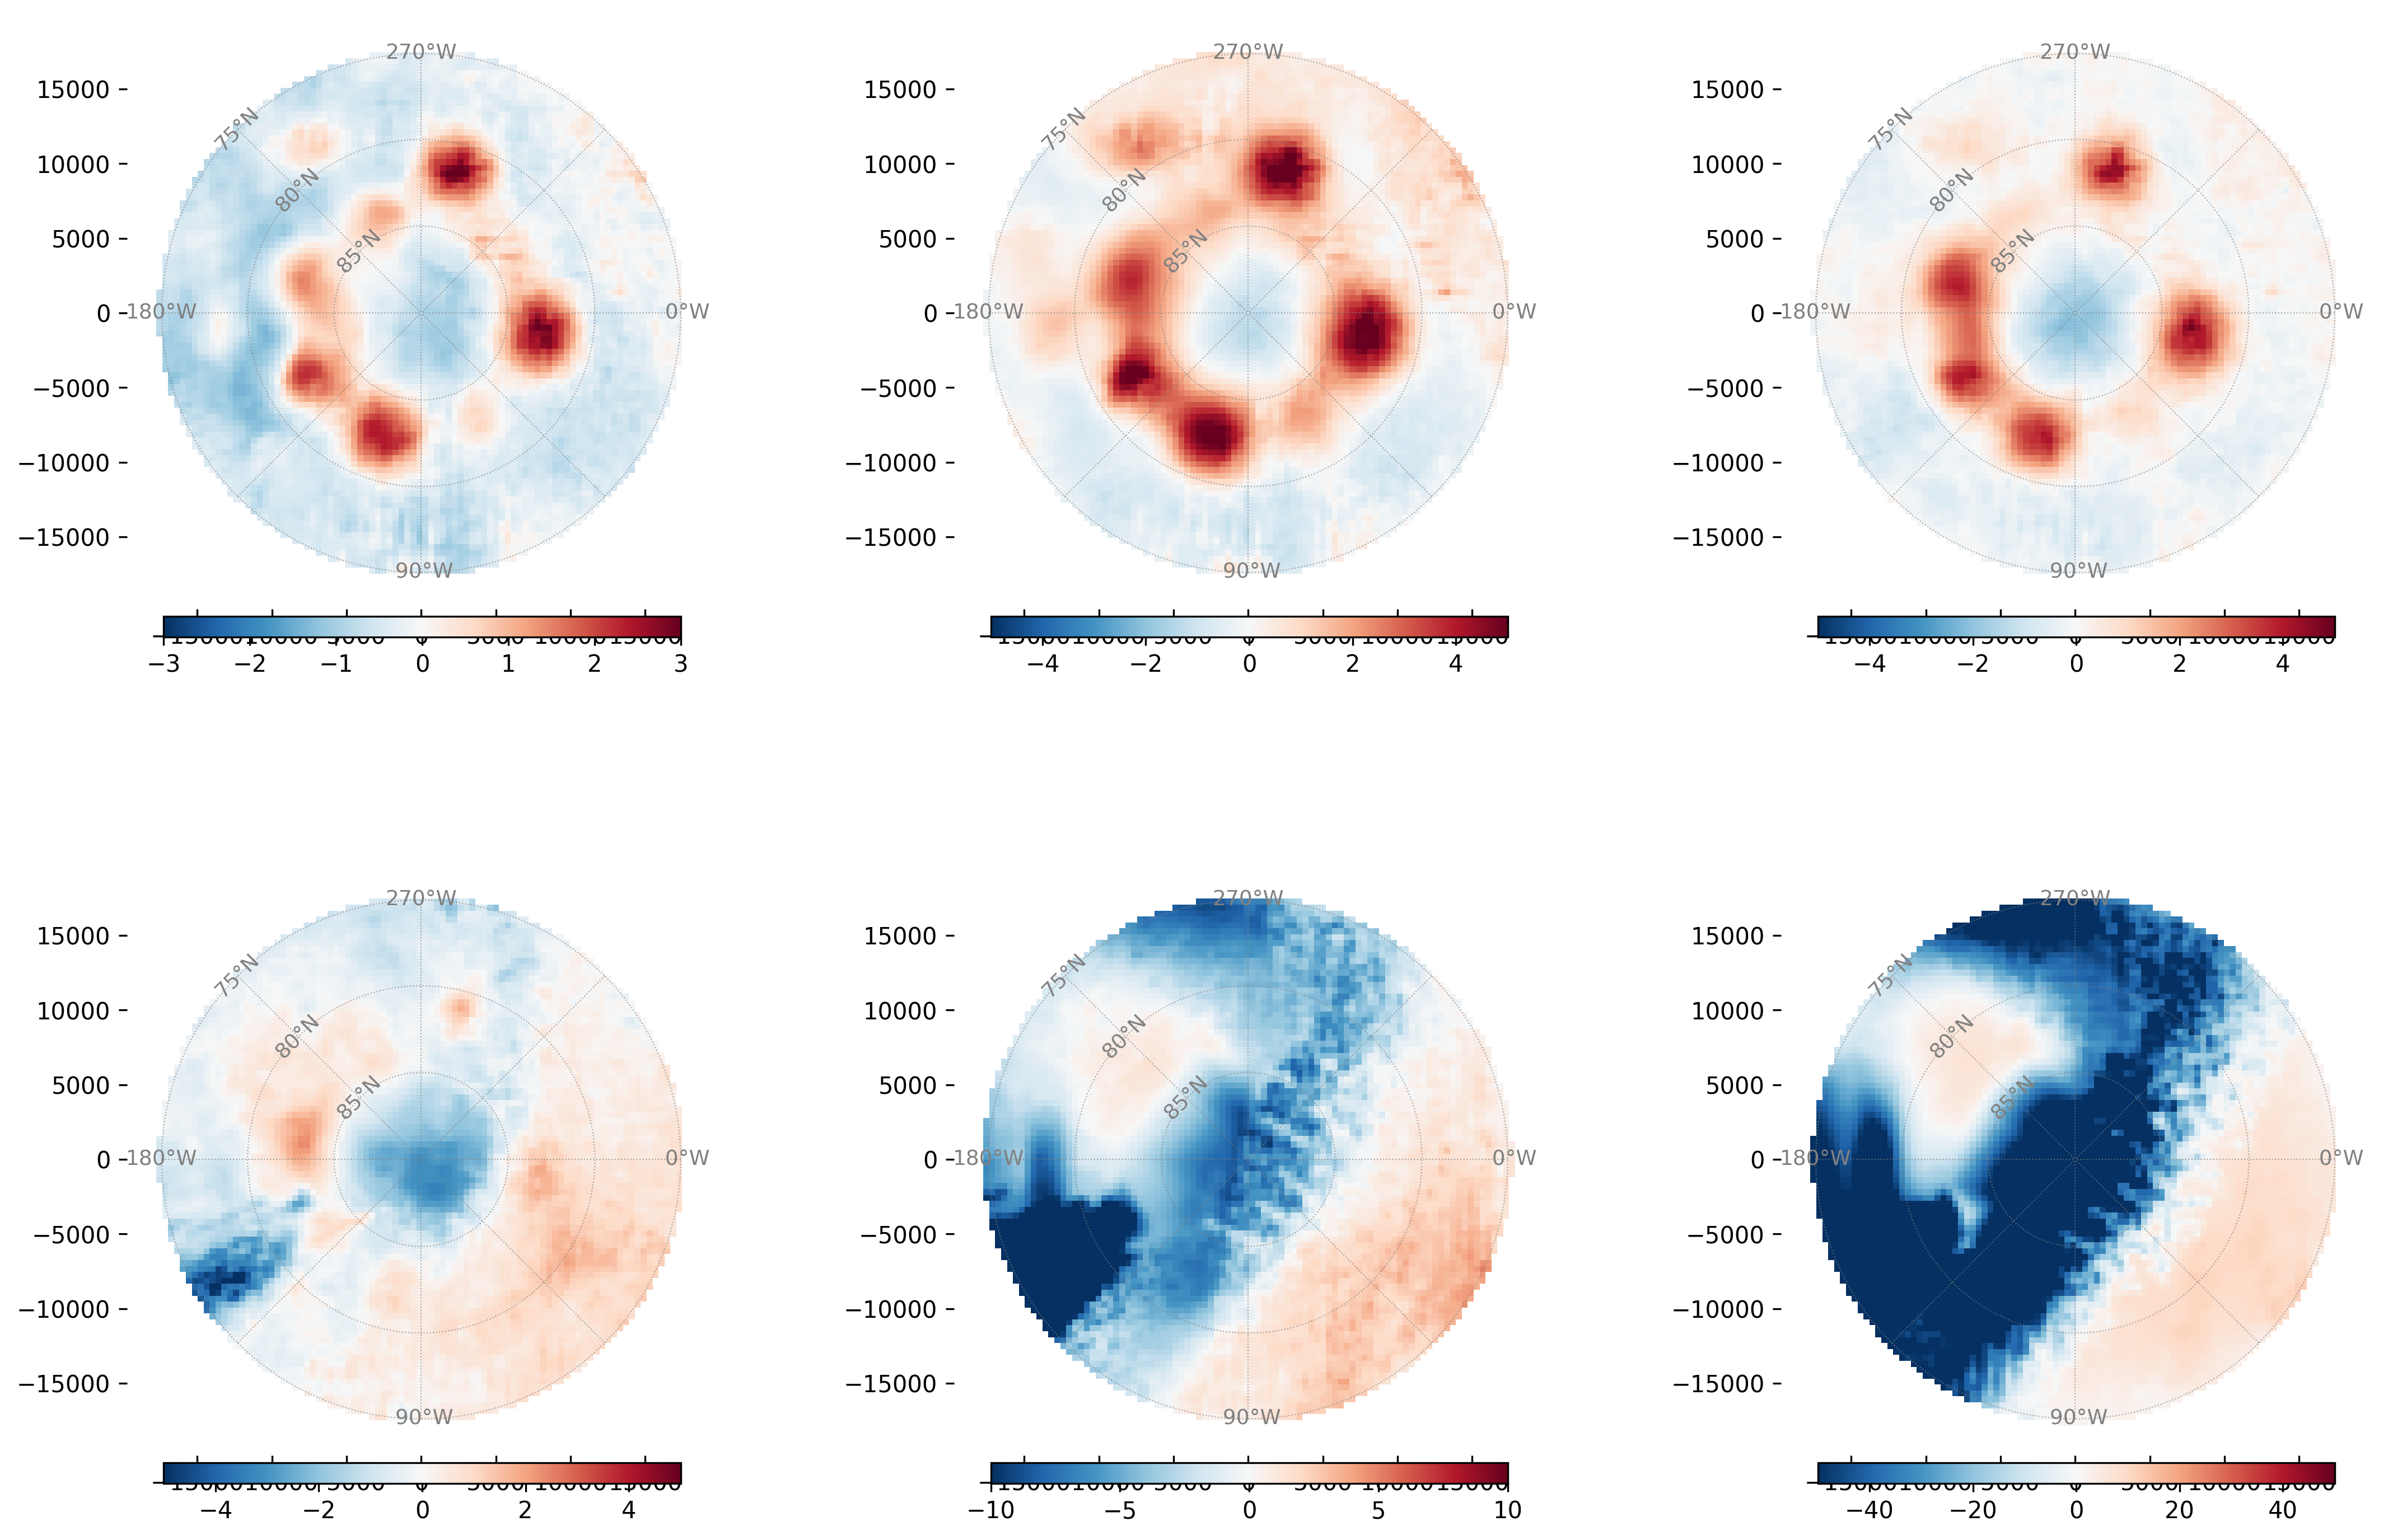

In [4]:
fig,axs=plt.subplots(2,3,figsize=(18,12), dpi=300)


def set_grid_ax(ax):
    
    def trans_coordinates(lat, lon):
            # Jupiter's radii in km
            R_equator = 71492.0  # Equatorial radius
            R_polar = 66854.0    # Polar radius

            # Convert lat and lon to radians
            lat_rad = np.radians(lat)
            lon_rad = np.radians(lon)

            # Calculate the radius for each latitude (ellipsoidal shape of Jupiter)
            R = R_equator * np.cos(lat_rad)**2 + R_polar * np.sin(lat_rad)**2

            # Compute Cartesian coordinates
            x = R * np.cos(lat_rad) * np.cos(lon_rad)
            y = R * np.cos(lat_rad) * np.sin(lon_rad)

            return x, y
    
    for ll in [85,80,75]:
        lons=np.linspace(-180, 180, 100)
        lats=np.linspace(ll, ll, 100)
        xg,yg=trans_coordinates(lats, lons)
        color='gray'
        # if ll==75: lw=1 ; linestyle="-"; color='k'
        # else: 
        lw=0.5; linestyle=":"
        ax.plot(xg,yg,linestyle=linestyle, color=color, lw=lw, alpha=0.7)
        
        x,y=trans_coordinates(ll, 135)
        ax.text(x,y, f"{ll:2.0f}°N", color='gray', va='center', ha="center", rotation=45, fontsize=9)


    for oo in np.linspace(0,315,8):
 
        lons=np.linspace(oo, oo, 100)
        lats=np.linspace(75, 90, 100)
        xg,yg=trans_coordinates(lats, lons)
        ax.plot(xg,yg,":", color='gray', lw=0.5, alpha=0.7)
        if oo%90==0:
            x,y=trans_coordinates(75, oo)
            ha="center"
            va='center'
            if oo==0: oo=360
            ax.text(x,y, f"{360-oo:3.0f}°W", color='gray',  va=va, ha=ha, fontsize=9)

levels=[np.linspace(-50, 50, 11),
        np.linspace(-10, 10, 11),
        np.linspace(-5, 5, 11),
        np.linspace(-5, 5, 11),
        np.linspace(-5, 5, 11),
        np.linspace(-3, 3, 13)]
for i in range(6):
    ax=axs.flatten()[i]
    for spine in ax.spines.values():
        spine.set_visible(False)

    set_grid_ax(ax)
    # sc=ax.scatter([],[], c=[], cmap=cmap, vmin=levels[ch][0], vmax=levels[ch][-1])
    sc=ax.scatter([],[], c=[], cmap='RdBu_r', vmin=levels[5-i][0], vmax=levels[5-i][-1])
    ax.pcolormesh(grid_x, grid_y, anomaly[5-i], cmap='RdBu_r', vmin=levels[5-i][0], vmax=levels[5-i][-1])
    cbar = plt.colorbar(sc, ax=ax, orientation='horizontal', shrink=0.75, aspect=25, pad = 0.01, extend='neither')
    ax.set_aspect('equal')



In [5]:


cpcs_index = np.array([1, 2, 3, 4, 5, 6, 7, 8])
cpcs_lon_min = np.array([-30, -75, -130, -165, 145, 95, 60, 20])
cpcs_lon_max = np.array([10, -45, -90, -135, 180, 135, 90, 60])
cpcs_lat_min = np.array([80, 82, 80.5, 80.5, 81, 82.5, 79, 82.5])
cpcs_lat_max = np.array([85, 85, 85, 85, 85, 86, 83.5, 85.5])

thera=[1, 0.2, 1, 1, 0.35, 0.35, 1, 0.35]

In [8]:
# read in profiles from ../profiles_in_grid_dry.h5
with h5py.File("../profiles_in_grid_dry.h5", "r") as h5f:
    shsnh3=h5f["shs_nh3"][:]
    ppmnh3=h5f["ppm_NH3"][:]

print(shsnh3.shape)

print(ppmnh3[50,50,:])
print(shsnh3[50,50,:])


(100, 100, 1600)
[3.54830000e+02 3.54830000e+02 3.54830000e+02 ... 4.35783282e-02
 4.35766289e-02 4.35749295e-02]
[2.55373483e-03 2.55373483e-03 2.55373483e-03 ... 3.19646949e-07
 3.19634484e-07 3.19622020e-07]


In [20]:
with h5py.File("../thetas_in_grid_dry.h5", "r") as f:
    # theta_total = f["thetas"][:]
    tbs_dry = f["tbs"][:,:,:]
print('tbs_dry', tbs_dry.shape)

with h5py.File("../thetas_in_grid_pseudo.h5", "r") as f:
    tbs_moist = f["tbs"][:,:,:]



with h5py.File("../cpc_dry/bin/juno_forward_mwr_polarmean-main.nc", "r") as f:
    polarmean_dry = f["radiance"][0,::4,0,0][2:]

with h5py.File("../cpc_moist/bin/juno_forward_mwr_polarmean_pseudo-main.nc", "r") as f:
    polarmean_pseudo = f["radiance"][0,::4,0,0][2:]

print('polarmean_dry', polarmean_dry.shape)
print('polarmean_pseudo', polarmean_pseudo.shape)


tbs_moist=tbs_moist-polarmean_pseudo
tbs_dry=tbs_dry-polarmean_dry

tbs_dry (100, 100, 4)
polarmean_dry (4,)
polarmean_pseudo (4,)


(100, 100) (100, 100) (6, 100, 100)


Text(-0.05, 1.1, 'b')

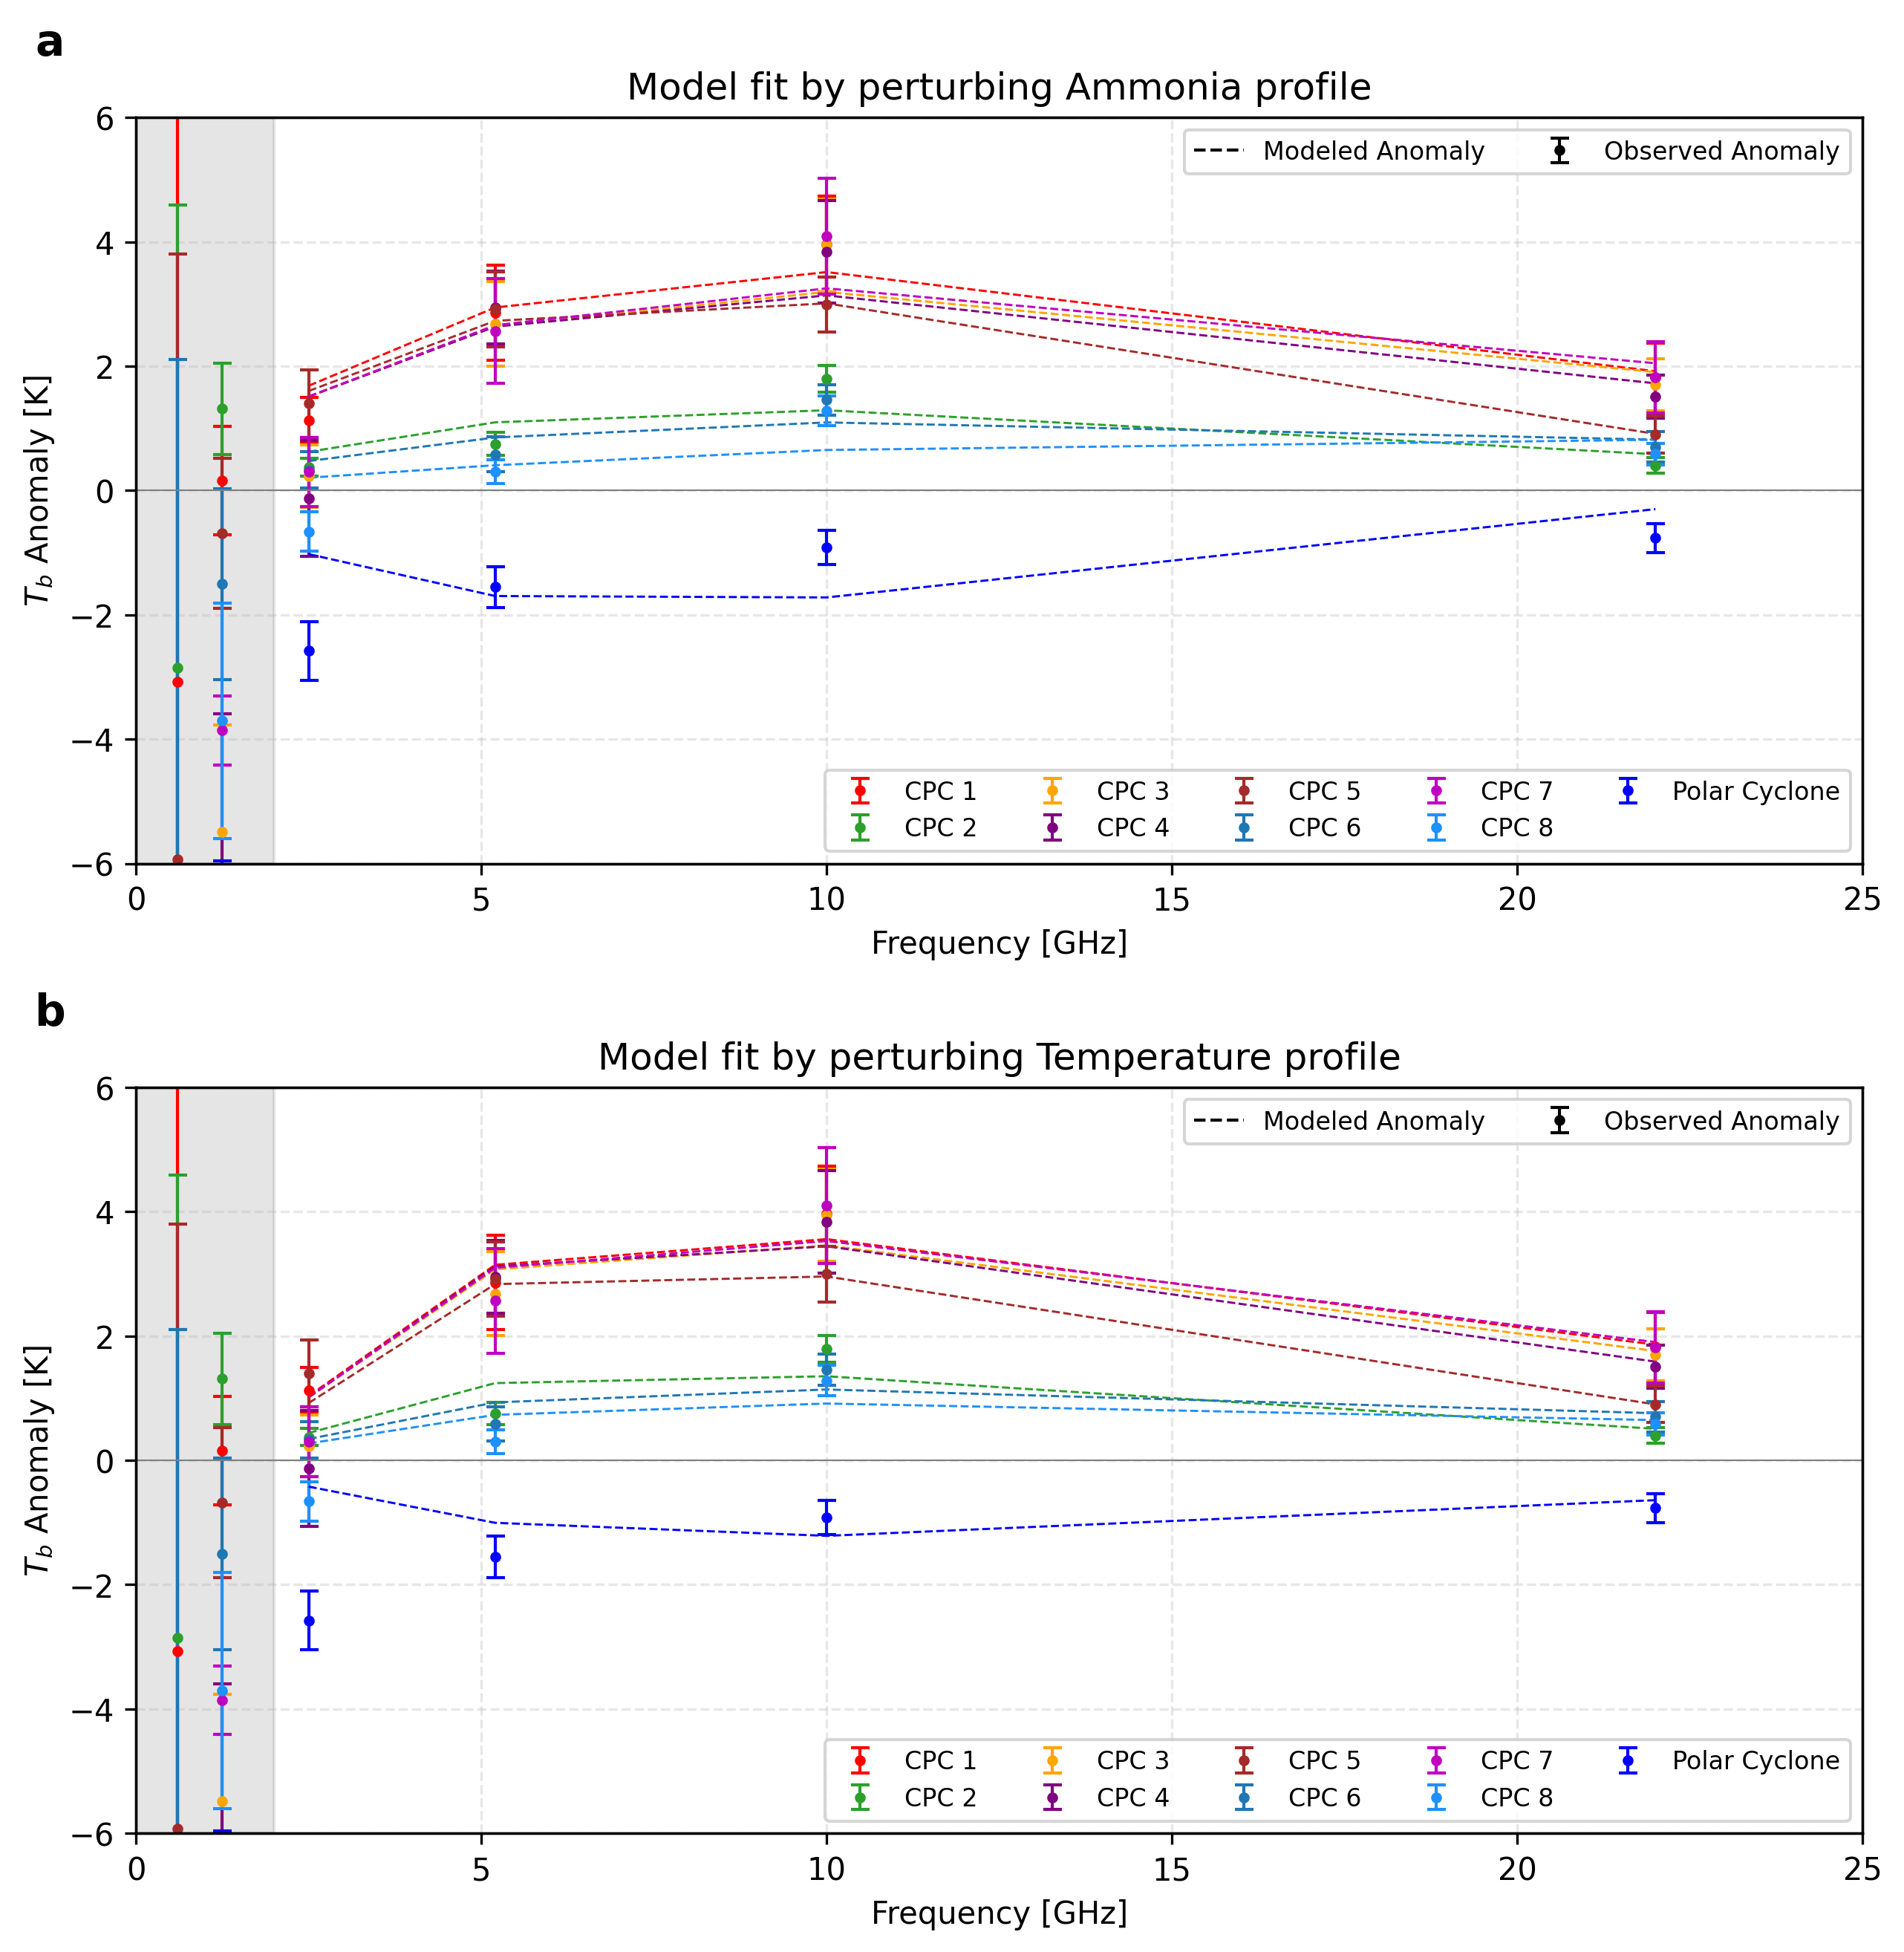

In [39]:

tb_anomaly = np.zeros((9, 6))
tb_anomaly_std = np.zeros((9, 6))


dry_mean = np.zeros((9, 4))
moist_mean = np.zeros((9, 4))

# plot the tb anomaly VS CHANNEL
fig, [ax1, ax2] = plt.subplots(2, 1, figsize=(10, 10), dpi=300, gridspec_kw={'hspace': 0.3})
colors = ['red', '#2ca02c', 'orange', 'purple', 'brown','#1f77b4', 'm', "dodgerblue", 'b', 'k']

# colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f']
xs=np.array([0.6,1.25,2.5,5.2,10,22])


## mask samples for each cpc
lon2d[lon2d>180]-=360


print(lon2d.shape, lat2d.shape, anomaly.shape)

for i in range(8):
    lon_mask = (lon2d >= cpcs_lon_min[i]) & (lon2d <= cpcs_lon_max[i]) & (anomaly[5,:,:] > thera[i])
    lat_mask = (lat2d >= cpcs_lat_min[i]) & (lat2d <= cpcs_lat_max[i]) & (anomaly[5,:,:] > thera[i])
    mask = lon_mask & lat_mask
    # print(np.count_nonzero(mask))


    tb_anomaly[i, :] = np.nanmean(anomaly[:,mask], axis=1)
    tb_anomaly_std[i, :] = np.nanstd(anomaly[:, mask], axis=1)

    dry_mean[i, :] = np.nanmean(tbs_dry[mask, :], axis=0)
    moist_mean[i, :] = np.nanmean(tbs_moist[mask,:], axis=0)




    # ax.plot(xs, tb_anomaly[i, :], , color=colors[i], linewidth=1)
    ax1.plot(xs[2:], dry_mean[i, :], linestyle='--',  color=colors[i], linewidth=0.7)
    ax1.errorbar(xs, tb_anomaly[i, :], yerr=tb_anomaly_std[i, :], fmt='.', markersize=5, capsize=3, color=colors[i], linewidth=1,label=f"CPC {i+1}")

    ax2.plot(xs[2:], moist_mean[i, :], linestyle='--',  color=colors[i], linewidth=0.7)
    ax2.errorbar(xs, tb_anomaly[i, :], yerr=tb_anomaly_std[i, :], fmt='.', markersize=5, capsize=3, color=colors[i], linewidth=1,label=f"CPC {i+1}")
    # ax2.plot(xs, temp_anomaly_mean[i, :], linestyle='--',  color=colors[i], linewidth=0.7)

# ##' center cyclone
mask =  lat2d >= 87.5
tb_anomaly[8, :] = np.nanmean(anomaly[:,mask], axis=1)
tb_anomaly_std[8, :] = np.nanstd(anomaly[:, mask], axis=1)
moist_mean[8, :] = np.nanmean(tbs_moist[mask,:], axis=0)
dry_mean[8, :] = np.nanmean(tbs_dry[mask,:], axis=0)

ax1.plot(xs[2:], dry_mean[8, :], linestyle='--',  color=colors[8], linewidth=0.7)
ax1.errorbar(xs, tb_anomaly[8, :], yerr=tb_anomaly_std[8, :], fmt='.', markersize=5, capsize=3, color=colors[8], linewidth=1,label=f"Polar Cyclone")

ax2.errorbar(xs, tb_anomaly[8, :], yerr=tb_anomaly_std[8, :], fmt='.', markersize=5, capsize=3, color=colors[8], linewidth=1,label=f"Polar Cyclone")
ax2.plot(xs[2:], moist_mean[8, :], linestyle='--',  color=colors[8], linewidth=0.7)

for ax in [ax1, ax2]:
    # ax.set_xscale('log')
    ax.set_ylim(-6, 6)
    ax.set_xlim(0, 25)
    ax.fill_between([0, 2], -6, 6, color='gray', alpha=0.2)

    ax.grid(linestyle='--', alpha=0.3)

    ax.axhline(0, color='gray', linestyle='-', linewidth=0.5)
    # ax.grid(linestyle='--',alpha=0.3)
    ax.legend(ncol=5, loc='lower right', fontsize=8)
    ax.set_xlabel("Frequency [GHz]")
    ax.set_ylabel("$T_b$ Anomaly [K]")

# add aditional legend with dummy lines
# In total 3x3 lines have been plotted

    axl1 = ax.twinx()
    axl1.set_ylim(-4, 6)
    axl1.errorbar([1], [-100], yerr=3, fmt='.', markersize=5, capsize=3, color="k", linewidth=1, label='Observed Anomaly')
    axl1.plot([], [], linestyle='--', color='black', linewidth=1, label='Modeled Anomaly')

    axl1.legend(ncol=2, loc='upper right', fontsize=8)
    axl1.get_yaxis().set_visible(False)

ax1.set_title('Model fit by perturbing Ammonia profile',  fontsize=12)
ax1.text(-0.05, 1.1, 'a', ha='center', va='center', fontweight='bold',fontsize=14, transform=ax1.transAxes)

ax2.set_title('Model fit by perturbing Temperature profile',  fontsize=12)
ax2.text(-0.05, 1.1, 'b', ha='center', va='center', fontweight='bold',fontsize=14, transform=ax2.transAxes)

# ax.legend()

(100, 100) (100, 100) (6, 100, 100)
group 1: 498 samples
group 2: 177 samples
(3, 6)


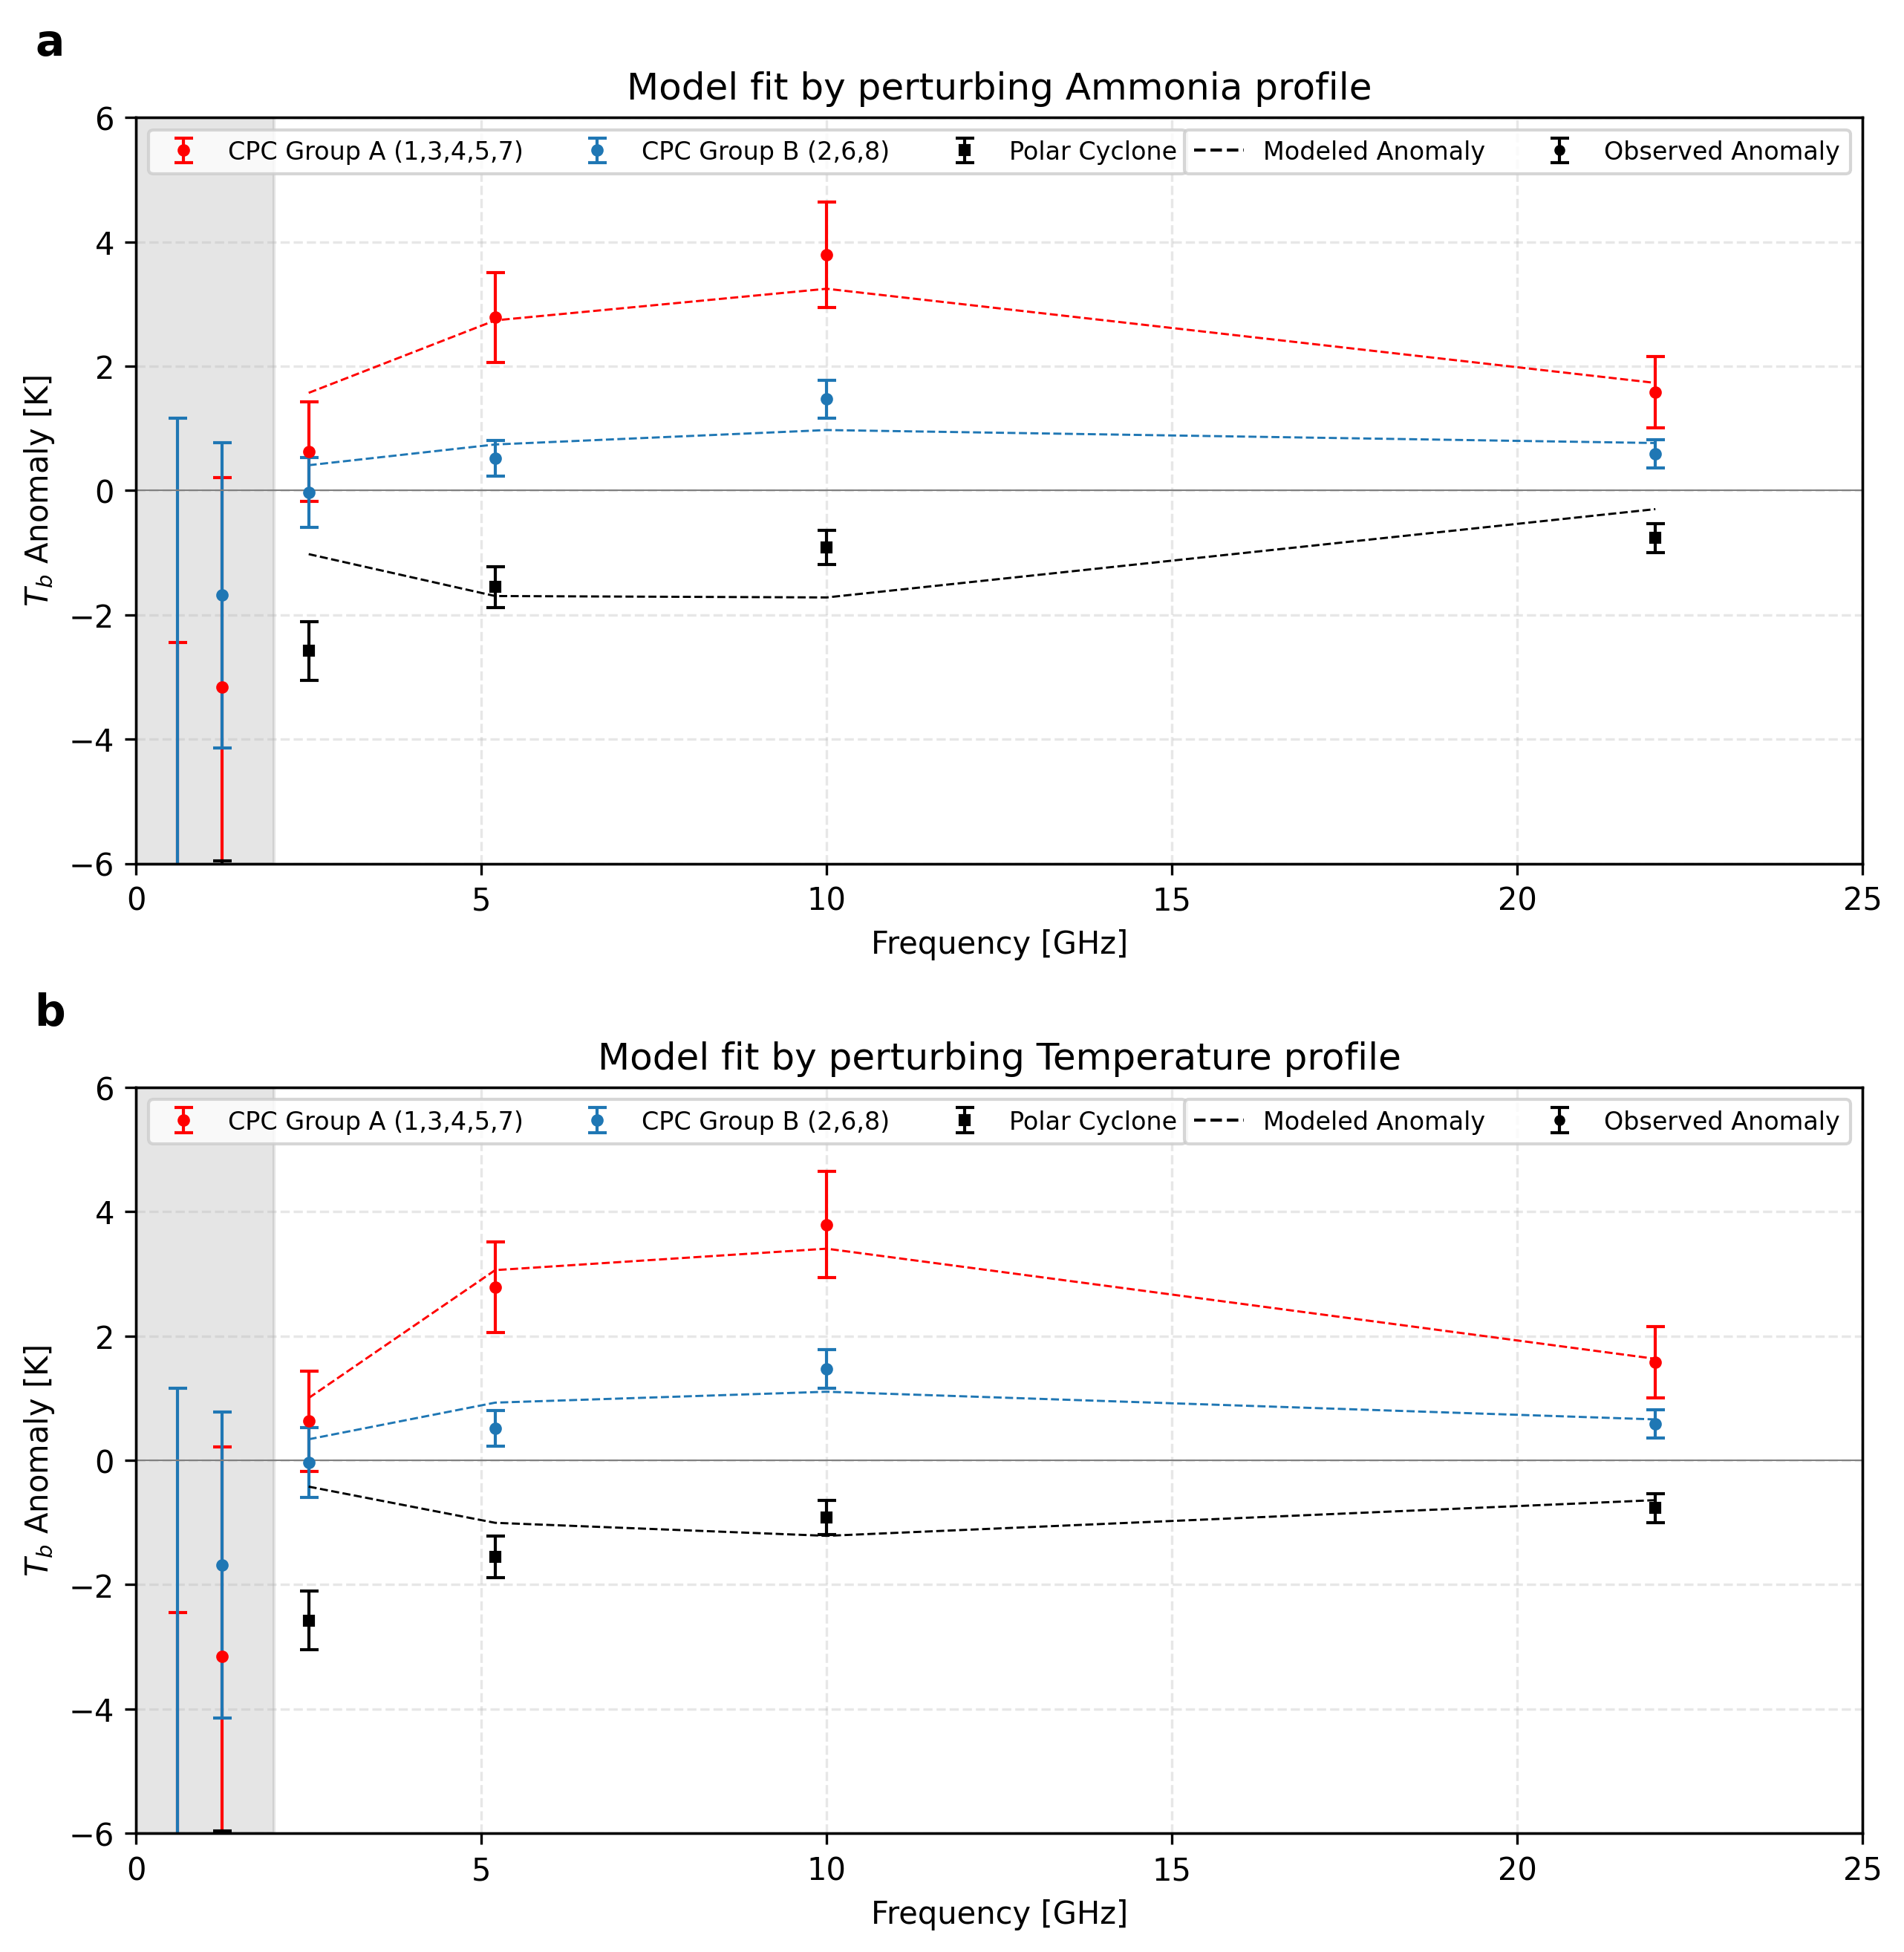

In [40]:

## group the CPCs and fit the group-mean anomaly
cpc_grp = [[1, 3, 4, 5, 7], [2, 6, 8]]
grp_labels = ["CPC Group A (1,3,4,5,7)", "CPC Group B (2,6,8)"]
grp_colors = ['red', '#1f77b4']

ngrp = len(cpc_grp)

tb_anomaly = np.zeros((ngrp + 1, 6))
tb_anomaly_std = np.zeros((ngrp + 1, 6))

dry_mean = np.zeros((ngrp + 1, 4))
moist_mean = np.zeros((ngrp + 1, 4))

# plot the tb anomaly VS CHANNEL
fig, [ax1, ax2] = plt.subplots(2, 1, figsize=(10, 10), dpi=300, gridspec_kw={'hspace': 0.3})
xs = np.array([0.6, 1.25, 2.5, 5.2, 10, 22])

## mask samples for each cpc
lon2d[lon2d > 180] -= 360

print(lon2d.shape, lat2d.shape, anomaly.shape)

## per-CPC sample masks
cpc_masks = []
for i in range(8):
    lon_mask = (lon2d >= cpcs_lon_min[i]) & (lon2d <= cpcs_lon_max[i]) & (anomaly[5, :, :] > thera[i])
    lat_mask = (lat2d >= cpcs_lat_min[i]) & (lat2d <= cpcs_lat_max[i]) & (anomaly[5, :, :] > thera[i])
    cpc_masks.append(lon_mask & lat_mask)

## group mean over ALL samples of the member CPCs (pooled samples, not mean of means)
for ig in range(ngrp):
    mask = np.zeros_like(cpc_masks[0], dtype=bool)
    for cpc in cpc_grp[ig]:
        mask |= cpc_masks[cpc - 1]     # cpc_grp holds 1-based CPC ids
    print(f"group {ig+1}: {np.count_nonzero(mask)} samples")

    tb_anomaly[ig, :] = np.nanmean(anomaly[:, mask], axis=1)
    tb_anomaly_std[ig, :] = np.nanstd(anomaly[:, mask], axis=1)

    dry_mean[ig, :] = np.nanmean(tbs_dry[mask, :], axis=0)
    moist_mean[ig, :] = np.nanmean(tbs_moist[mask, :], axis=0)

    ax1.plot(xs[2:], dry_mean[ig, :], linestyle='--', color=grp_colors[ig], linewidth=0.7)
    ax1.errorbar(xs, tb_anomaly[ig, :], yerr=tb_anomaly_std[ig, :], fmt='o', markersize=3,
                 capsize=3, color=grp_colors[ig], linewidth=1, label=grp_labels[ig])

    ax2.plot(xs[2:], moist_mean[ig, :], linestyle='--', color=grp_colors[ig], linewidth=0.7)
    ax2.errorbar(xs, tb_anomaly[ig, :], yerr=tb_anomaly_std[ig, :], fmt='o', markersize=3,
                 capsize=3, color=grp_colors[ig], linewidth=1, label=grp_labels[ig])

# ##' center cyclone
mask = lat2d >= 87.5
tb_anomaly[ngrp, :] = np.nanmean(anomaly[:, mask], axis=1)
tb_anomaly_std[ngrp, :] = np.nanstd(anomaly[:, mask], axis=1)
moist_mean[ngrp, :] = np.nanmean(tbs_moist[mask, :], axis=0)
dry_mean[ngrp, :] = np.nanmean(tbs_dry[mask, :], axis=0)

ax1.plot(xs[2:], dry_mean[ngrp, :], linestyle='--', color='k', linewidth=0.7)
ax1.errorbar(xs, tb_anomaly[ngrp, :], yerr=tb_anomaly_std[ngrp, :], fmt='s', markersize=3,
             capsize=3, color='k', linewidth=1, label="Polar Cyclone")

ax2.plot(xs[2:], moist_mean[ngrp, :], linestyle='--', color='k', linewidth=0.7)
ax2.errorbar(xs, tb_anomaly[ngrp, :], yerr=tb_anomaly_std[ngrp, :], fmt='s', markersize=3,
             capsize=3, color='k', linewidth=1, label="Polar Cyclone")

for ax in [ax1, ax2]:
    # ax.set_xscale('log')
    ax.set_ylim(-6, 6)
    ax.set_xlim(0, 25)
    ax.fill_between([0, 2], -6, 6, color='gray', alpha=0.2)
    ax.axhline(0, color='gray', linestyle='-', linewidth=0.5)
    # ax.grid(linestyle='--',alpha=0.3)
    ax.legend(ncol=3, loc='upper left', fontsize=8)
    ax.set_xlabel("Frequency [GHz]")
    ax.set_ylabel("$T_b$ Anomaly [K]")

    ax.grid(linestyle='--', alpha=0.3)

# add aditional legend with dummy lines

    axl1 = ax.twinx()
    axl1.set_ylim(-4, 6)
    axl1.errorbar([1], [-100], yerr=3, fmt='.', markersize=5, capsize=3, color="k", linewidth=1, label='Observed Anomaly')
    axl1.plot([], [], linestyle='--', color='black', linewidth=1, label='Modeled Anomaly')

    axl1.legend(ncol=2, loc='upper right', fontsize=8)
    axl1.get_yaxis().set_visible(False)

ax1.set_title('Model fit by perturbing Ammonia profile', fontsize=12)
ax1.text(-0.05, 1.1, 'a', ha='center', va='center', fontweight='bold', fontsize=14, transform=ax1.transAxes)

ax2.set_title('Model fit by perturbing Temperature profile', fontsize=12)
ax2.text(-0.05, 1.1, 'b', ha='center', va='center', fontweight='bold', fontsize=14, transform=ax2.transAxes)

# fill x between 0.6 and 1.25 GHz



print(tb_anomaly_std.shape)

# Save the model fit results to an HDF5 file
with h5py.File("modelfit.h5", "w") as outhdf:
    outhdf.create_dataset("tb_anomaly", data=tb_anomaly)
    outhdf.create_dataset("tb_anomaly_std", data=tb_anomaly_std)
    outhdf.create_dataset("dry_mean", data=dry_mean)
    outhdf.create_dataset("moist_mean", data=moist_mean)


In [ ]:
## CPC-mean retrieved NH3 (specific humidity) profiles -> cpcmean_nh3_profiles.h5
# ---------------------------------------------------------------- grid / obs
with h5py.File("../observation/tb_anomaly_grided_PJ51_PJ61_FA02.h5", "r") as h5f:
    anomaly = h5f["anomaly"][:]
    lon2d = h5f["longitude"][:]
    lat2d = h5f["latitude"][:]

lon2d[lon2d > 180] -= 360

# ---------------------------------------------------------------- CPC boxes
cpcs_index = np.array([1, 2, 3, 4, 5, 6, 7, 8])
cpcs_lon_min = np.array([-30, -75, -130, -165, 145, 95, 60, 20])
cpcs_lon_max = np.array([10, -45, -90, -135, 180, 135, 90, 60])
cpcs_lat_min = np.array([80, 82, 80.5, 80.5, 81, 82.5, 79, 82.5])
cpcs_lat_max = np.array([85, 85, 85, 85, 85, 86, 83.5, 85.5])

thera = [1, 0.2, 1, 1, 0.35, 0.35, 1, 0.35]

# ---------------------------------------------------------------- profiles
with h5py.File("../profiles_in_grid_dry.h5", "r") as h5f:
    shsnh3 = h5f["shs_nh3"][:]          # (100, 100, 1600)

shsnh3[shsnh3 == 0] = np.nan            # unretrieved pixels

with h5py.File("../cpc_dry/bin/juno_forward_mwr_polarmean-main.nc", "r") as f:
    pressure = f["press"][0, :, 0, 0] * 1e-5     # bar

with h5py.File("../cpc_dry/bin/juno_mwr_forward_polarmean_profiles.h5", "r") as f:
    bg_nh3_sh = f["nh3_sh"][:]          # polar-mean background profile

nlev = shsnh3.shape[-1]

# ---------------------------------------------------------------- CPC means
ncpc = 8
cpc_mean = np.full((ncpc + 1, nlev), np.nan)
cpc_std = np.full((ncpc + 1, nlev), np.nan)
nsample = np.zeros(ncpc + 1, dtype=np.int32)

for i in range(ncpc):
    lon_mask = (lon2d >= cpcs_lon_min[i]) & (lon2d <= cpcs_lon_max[i]) & (anomaly[5, :, :] > thera[i])
    lat_mask = (lat2d >= cpcs_lat_min[i]) & (lat2d <= cpcs_lat_max[i]) & (anomaly[5, :, :] > thera[i])
    mask = lon_mask & lat_mask
    nsample[i] = np.count_nonzero(mask)

    cpc_mean[i, :] = np.nanmean(shsnh3[mask, :], axis=0)
    cpc_std[i, :] = np.nanstd(shsnh3[mask, :], axis=0)
    print(f"CPC {i+1}: {nsample[i]} samples")

## central polar cyclone
mask = lat2d >= 87.5
nsample[ncpc] = np.count_nonzero(mask)
cpc_mean[ncpc, :] = np.nanmean(shsnh3[mask, :], axis=0)
cpc_std[ncpc, :] = np.nanstd(shsnh3[mask, :], axis=0)
print(f"Polar Cyclone: {nsample[ncpc]} samples")

# ---------------------------------------------------------------- output
with h5py.File("cpcmean_nh3_profiles.h5", "w") as outhdf:
    d = outhdf.create_dataset("shs_nh3_mean", data=cpc_mean[:ncpc, :])
    d.attrs["description"] = "CPC-mean retrieved NH3 specific humidity profile, CPC 1-8"
    d = outhdf.create_dataset("shs_nh3_std", data=cpc_std[:ncpc, :])
    d.attrs["description"] = "standard deviation over the samples of each CPC"
    outhdf.create_dataset("nsample", data=nsample[:ncpc])
    outhdf.create_dataset("cpc_index", data=cpcs_index)
    outhdf.create_dataset("cpc_lon_min", data=cpcs_lon_min)
    outhdf.create_dataset("cpc_lon_max", data=cpcs_lon_max)
    outhdf.create_dataset("cpc_lat_min", data=cpcs_lat_min)
    outhdf.create_dataset("cpc_lat_max", data=cpcs_lat_max)
    outhdf.create_dataset("tb_threshold", data=np.array(thera))
    ## central polar cyclone (lat >= 87.5), kept separately from the eight CPCs
    outhdf.create_dataset("shs_nh3_mean_polar", data=cpc_mean[ncpc, :])
    outhdf.create_dataset("shs_nh3_std_polar", data=cpc_std[ncpc, :])
    d = outhdf.create_dataset("pressure", data=pressure)
    d.attrs["units"] = "bar"
    d = outhdf.create_dataset("shs_nh3_background", data=bg_nh3_sh)
    d.attrs["description"] = "polar-mean background NH3 specific humidity profile"

print("saved cpcmean_nh3_profiles.h5", cpc_mean[:ncpc, :].shape)
